Conor Murray Lab 2
Cereal Wars

A large grocery store chain, GrocerMart, wants to optimize its cereal aisle to maximize sales and customer satisfaction. The company's brand management team suspects that customer preferences are not just about taste but are heavily influenced by nutritional content and brand perception. As a business analyst intern, you've been tasked with analyzing a dataset of popular cereals from different manufacturers to provide data-driven recommendations. Your goal is to identify patterns, trends, and key characteristics that define the cereal market and help GrocerMart make informed decisions about product placement, promotions, and inventory. 

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('cereal_with missing.csv')
print(df.shape)
df.head(10)

(74, 16)


,ID,name,mfr,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,1001,Maypo,A,100.0,4,1,0,0.0,16.0,3,95.0,25,2,1.0,1.00,54.850917
1,1002,Trix,G,110.0,1,1,140,0.0,13.0,12,25.0,25,2,1.0,1.00,27.753301
2,1003,Total Corn Flakes,G,110.0,2,1,200,0.0,21.0,3,35.0,100,3,1.0,1.00,38.839746
3,1004,Kix,G,110.0,2,1,260,0.0,21.0,3,40.0,25,2,1.0,1.50,39.241114
4,1005,Cinnamon Toast Crunch,G,120.0,1,3,210,0.0,13.0,9,45.0,25,2,1.0,0.75,19.823573
5,1006,Golden Grahams,G,110.0,1,1,280,0.0,15.0,9,NaN,25,2,1.0,0.75,23.804043
6,1007,Cocoa Puffs,G,110.0,1,1,180,0.0,12.0,13,55.0,25,2,1.0,1.00,22.736446
7,1008,Lucky Charms,G,110.0,2,1,180,0.0,12.0,12,55.0,25,2,1.0,1.00,26.734515
8,1009,Triples,G,110.0,2,1,250,0.0,21.0,3,NaN,25,3,1.0,0.75,39.106174
9,1010,Wheaties Honey Gold,G,110.0,2,1,200,1.0,16.0,8,60.0,25,1,1.0,0.75,36.187559


In [20]:
df.describe()

,ID,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
count,74.000000,72.000000,74.000000,74.000000,74.000000,74.000000,74.000000,74.000000,69.000000,74.000000,74.000000,74.000000,74.000000,74.000000
mean,1037.500000,106.944444,2.513514,1.000000,162.364865,2.175676,14.729730,7.108108,101.594203,29.054054,2.216216,1.030811,0.821622,42.371787
std,21.505813,20.115084,1.075802,1.006826,82.769787,2.423391,3.891675,4.359111,72.108439,22.294352,0.832067,0.153416,0.235715,14.033712
min,1001.000000,50.000000,1.000000,0.000000,0.000000,0.000000,5.000000,0.000000,15.000000,0.000000,1.000000,0.500000,0.250000,18.042851
25%,1019.250000,100.000000,2.000000,0.000000,135.000000,0.250000,12.000000,3.000000,45.000000,25.000000,1.250000,1.000000,0.670000,32.449210
50%,1037.500000,110.000000,2.500000,1.000000,180.000000,2.000000,14.500000,7.000000,90.000000,25.000000,2.000000,1.000000,0.750000,40.253086
75%,1055.750000,112.500000,3.000000,1.000000,217.500000,3.000000,17.000000,11.000000,125.000000,25.000000,3.000000,1.000000,1.000000,50.520611
max,1074.000000,160.000000,6.000000,5.000000,320.000000,14.000000,23.000000,15.000000,330.000000,100.000000,3.000000,1.500000,1.500000,93.704912


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ID        74 non-null     int64  
 1   name      74 non-null     object 
 2   mfr       74 non-null     object 
 3   calories  72 non-null     float64
 4   protein   74 non-null     int64  
 5   fat       74 non-null     int64  
 6   sodium    74 non-null     int64  
 7   fiber     74 non-null     float64
 8   carbo     74 non-null     float64
 9   sugars    74 non-null     int64  
 10  potass    69 non-null     float64
 11  vitamins  74 non-null     int64  
 12  shelf     74 non-null     int64  
 13  weight    74 non-null     float64
 14  cups      74 non-null     float64
 15  rating    74 non-null     float64
dtypes: float64(7), int64(7), object(2)
memory usage: 9.4+ KB


For this data, I found no duplicate values this leads me to the conculsion that alothougb there is missing data we wont have to deal with repeated values. Since there is only a few missing values and each row is unique, we have two options to deal with the missing data. We can use pairwise deletion to only exclude the values when they effect the analysis we are conducting. If we wanted to impute it, the best option would be simple imputation. Since the missing values are in the caloire&potassium content part of the data we can use summary statistis to get a good estiamte of the missing values. Since calorie and potassium content often have much in common with protien, fiber, carbs, and sugar content, we can use these known values compared to known calorie or potassium values to then estimate the relation between our known and missing values.

,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,weight,cups,rating
calories,1.000000,0.038579,0.513157,0.296004,-0.294550,0.274462,0.578144,-0.069364,0.273602,0.697916,0.086263,-0.693911
protein,0.038579,1.000000,0.202353,0.011559,0.514006,-0.036743,-0.286584,0.613205,0.054800,0.230671,-0.242099,0.467162
fat,0.513157,0.202353,1.000000,0.000822,0.014036,-0.284934,0.287152,0.180326,-0.030514,0.221714,-0.157579,-0.405050
sodium,0.296004,0.011559,0.000822,1.000000,-0.070735,0.328409,0.037059,-0.025550,0.331576,0.312534,0.119584,-0.383012
fiber,-0.294550,0.514006,0.014036,-0.070735,1.000000,-0.379084,-0.150949,0.911008,-0.038717,0.246292,-0.513697,0.603411
carbo,0.274462,-0.036743,-0.284934,0.328409,-0.379084,1.000000,-0.452069,-0.363858,0.253579,0.144805,0.358284,0.055941
sugars,0.578144,-0.286584,0.287152,0.037059,-0.150949,-0.452069,1.000000,0.008604,0.072954,0.460547,-0.032436,-0.755955
potass,-0.069364,0.613205,0.180326,-0.025550,0.911008,-0.363858,0.008604,1.000000,-0.010857,0.419928,-0.519503,0.412037
vitamins,0.273602,0.054800,-0.030514,0.331576,-0.038717,0.253579,0.072954,-0.010857,1.000000,0.320435,0.133630,-0.214481
weight,0.697916,0.230671,0.221714,0.312534,0.246292,0.144805,0.460547,0.419928,0.320435,1.000000,-0.201715,-0.300461


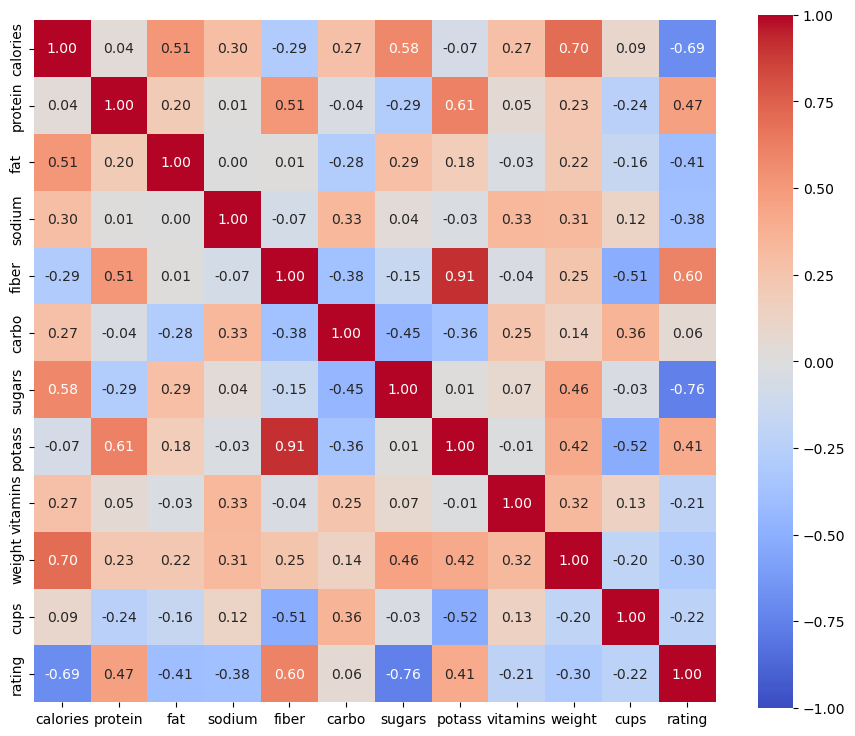

In [49]:
numeric_cols = ["calories", "protein", "fat", "sodium", "fiber", "carbo", "sugars", "potass", "vitamins", "weight", "cups", "rating"]
corr_matrix = df[numeric_cols].corr()
display(corr_matrix)
plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.show()

In [51]:
mfr_counts = df["mfr"].value_counts()
mfr_counts = mfr_counts.sort_index()
print("Number of cereals per manufacturer:")
print(mfr_counts)

Number of cereals per manufacturer:
mfr
A     1
G    22
K    23
N     5
P     9
Q     7
R     7
Name: count, dtype: int64


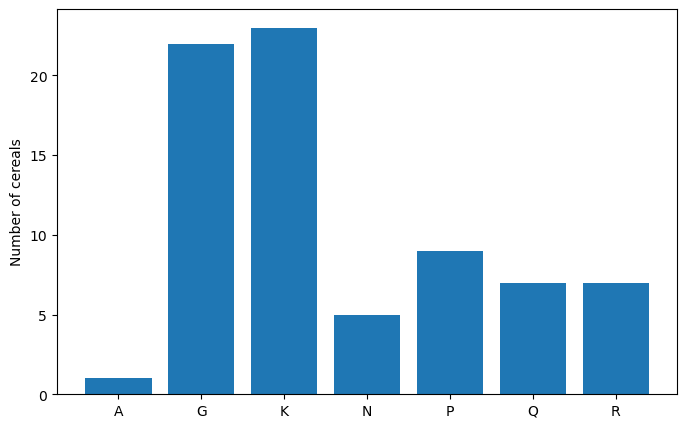

In [50]:
plt.figure(figsize=(8, 5))
plt.bar(mfr_counts.index, mfr_counts.values)
plt.ylabel("Number of cereals")
plt.show()

There are 2 dominant players in this market both manufacterer G and K are leading the market by a large margin compared to other companies. K has a slight advantage and is the largest supplier in this data set.

In [42]:
mfr_list = sorted(df["mfr"].unique())
ratings_by_mfr = []
for m in mfr_list:
    mask = df["mfr"] == m
    ratings_by_mfr.append(df.loc[mask, "rating"])

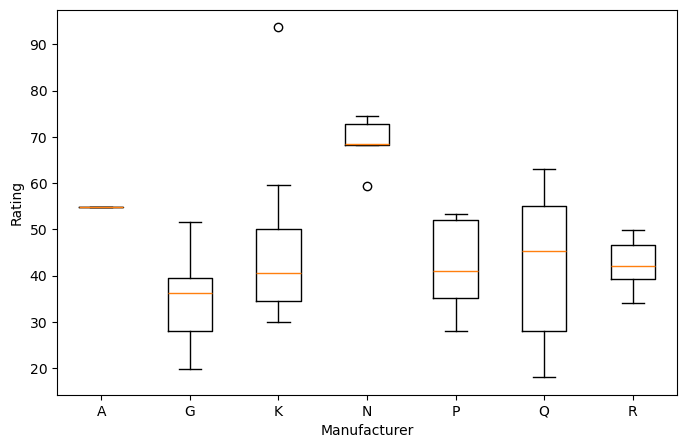

In [43]:
plt.figure(figsize=(8, 5))
plt.boxplot(ratings_by_mfr, tick_labels=mfr_list)
plt.xlabel("Manufacturer")
plt.ylabel("Rating")
plt.show()

Manufactuere K had the highest range of ratings with a range from less than 30 to over 90 including the outlier. This is over 60 incirments. Comparebly N manufacter has the smallest amount of variablilty with all thier ratings being extremely high. if we dont include outliers then Q becomes the manufacterer with the widest range from less than 20 to over 60.

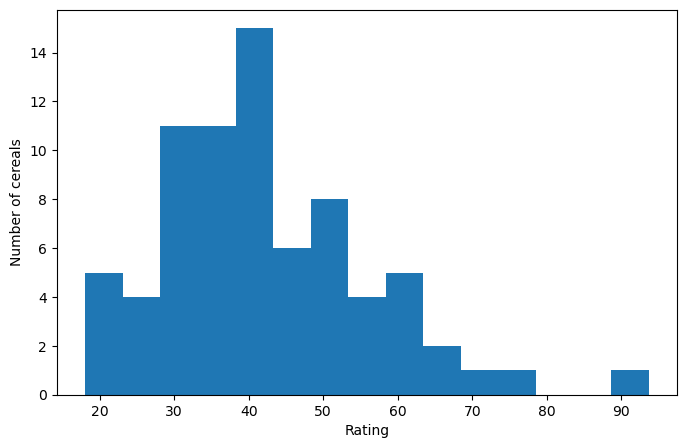

In [36]:
plt.figure(figsize=(8, 5))
plt.hist(df["rating"], bins=15)
plt.xlabel("Rating")
plt.ylabel("Number of cereals")
plt.show()

This graph is right skewed making it positive and has a very tall peak in the middle without an even curve giving it high kurtosis as well. This means many of the values fall witin close to the mode, but any that dont are massivey larger or smalle ratings. This tells us most customers give a rating of around 40, but any customers who love or hate the cereal wil give vastly different ratings, with a small tendency towards worse ratings as we can see the left side of the bell curve is heavier.


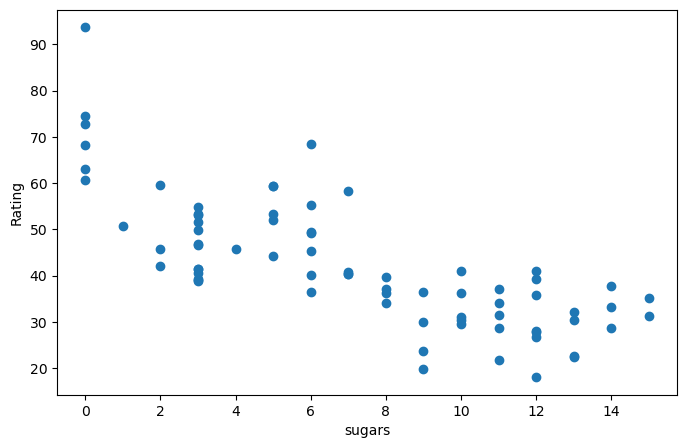

Correlation of rating with sugars = -0.756



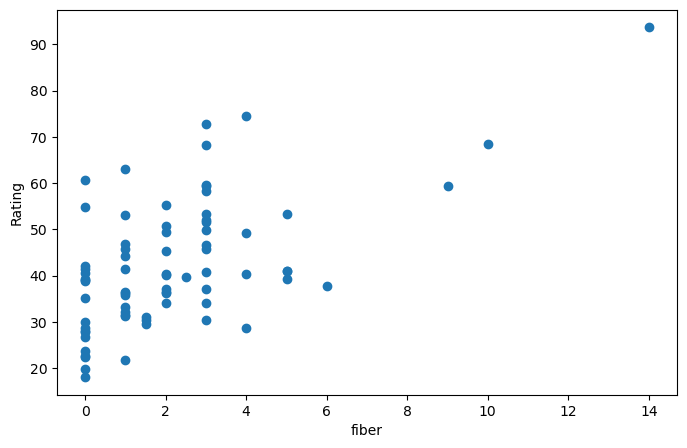

Correlation of rating with fiber = 0.603



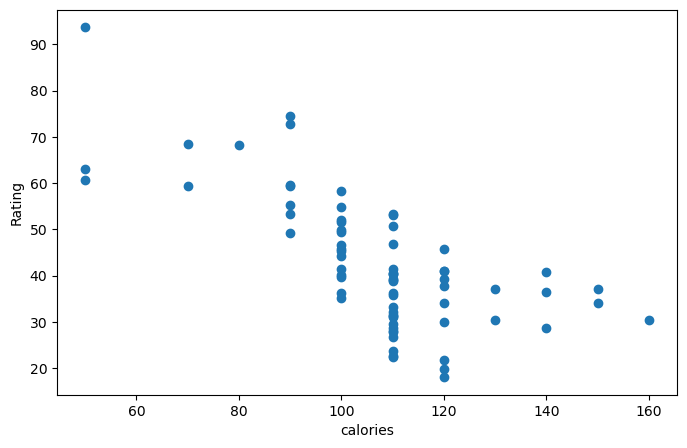

Correlation of rating with calories = -0.694



In [38]:
x_cols = ["sugars", "fiber", "calories"]
for col in x_cols:
    plt.figure(figsize=(8, 5))
    plt.scatter(df[col], df["rating"])
    plt.xlabel(col)
    plt.ylabel("Rating")
    plt.show()
    print("Correlation of rating with", col, "=", round(df["rating"].corr(df[col]), 3))
    print()

This relationship shows that while fiber has a positive relationship with ratings, both calories and sugar have a negative relationship. This finding can point to people rating healthier cereals higher than non-helathy ones.

My first recomendation is to focus both Q and K manufacterers on making healthier products, the data shows that products high in sugar and calories tend to get rated worse so ensuring that the largest producers are making the higher rated cereals boosts total revenue and total positive reviews.
My second recomendation is to focus on increasing potassium content in cereal becuase this can lead to more fiber sugar as we found they are strongly correlated as well as higher fiber content being correlated to higher ratings.